# Melbourne Housing Price Prediction

A self-contained, from-scratch machine learning walkthrough using the cleaned Melbourne housing dataset in `Resources/clean_melbourne_housing.csv`.

The notebook follows one path: inspect the data, prepare numerical and categorical features, train linear regression with NumPy gradient descent, compare loss functions, and evaluate price estimates on held-out homes. The model implementation lives in this notebook; pandas is used for data handling and Matplotlib for plots.

## 1. Load the data

`Price` is the target in Australian dollars. `Rooms`, `Distance`, `Bathroom`, and `Car` are numeric inputs. `Type` and `Region` are categorical inputs. `LogPrice` is excluded because it is a transformed version of the target and would leak the answer into the features.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 42
DATA_PATH = Path("Resources/clean_melbourne_housing.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Run this notebook from the project folder.")

data = pd.read_csv(DATA_PATH)
required_columns = {"Rooms", "Type", "Price", "Distance", "Bathroom", "Car", "Region"}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if data[list(required_columns)].isna().any().any():
    raise ValueError("The selected dataset columns contain missing values; clean them before training.")

print(f"Rows: {len(data):,} | Columns: {len(data.columns)}")
display(data.head())

Rows: 17,698 | Columns: 8


,Rooms,Type,Price,Distance,Bathroom,Car,Region,LogPrice
0,2.0,h,1480000.0,2.5,1.0,1.0,Northern Metropolitan,14.207553
1,2.0,h,1035000.0,2.5,1.0,0.0,Northern Metropolitan,13.849912
2,3.0,h,1465000.0,2.5,2.0,0.0,Northern Metropolitan,14.197366
3,3.0,h,850000.0,2.5,2.0,1.0,Northern Metropolitan,13.652992
4,4.0,h,1600000.0,2.5,1.0,2.0,Northern Metropolitan,14.285514


In [2]:
data[["Rooms", "Distance", "Bathroom", "Car", "Price"]].describe().round(2)

,Rooms,Distance,Bathroom,Car,Price
count,17698.00,17698.00,17698.00,17698.0,17698.00
mean,3.05,11.16,1.57,1.7,1060457.32
std,0.94,6.65,0.66,1.0,530813.10
min,1.00,0.00,0.00,0.0,85000.00
25%,2.00,6.50,1.00,1.0,660000.00
50%,3.00,10.40,1.00,2.0,912500.00
75%,4.00,13.90,2.00,2.0,1345000.00
max,7.00,48.10,3.50,18.0,2372500.00


## 2. Split and preprocess

We reserve 20% of the homes for evaluation. Scaling values are learned from the training portion only, then reused for the held-out portion. Numeric inputs and the price target are standardized to keep gradient descent updates on comparable scales. Categorical inputs become one-hot columns.

In [3]:
numeric_features = ["Rooms", "Distance", "Bathroom", "Car"]
categorical_features = ["Type", "Region"]
target_name = "Price"

rng = np.random.default_rng(RANDOM_SEED)
permutation = rng.permutation(len(data))
split_at = int(len(data) * 0.8)
train_rows = data.iloc[permutation[:split_at]].reset_index(drop=True)
test_rows = data.iloc[permutation[split_at:]].reset_index(drop=True)

# One-hot encode each split, then align test columns to the training feature set.
X_train_categories = pd.get_dummies(train_rows[categorical_features], dtype=float)
X_test_categories = pd.get_dummies(test_rows[categorical_features], dtype=float)
X_test_categories = X_test_categories.reindex(columns=X_train_categories.columns, fill_value=0.0)

X_train_numeric = train_rows[numeric_features].to_numpy(dtype=float)
X_test_numeric = test_rows[numeric_features].to_numpy(dtype=float)
x_mean = X_train_numeric.mean(axis=0)
x_scale = X_train_numeric.std(axis=0)
x_scale[x_scale == 0] = 1.0

X_train = np.column_stack(((X_train_numeric - x_mean) / x_scale, X_train_categories.to_numpy()))
X_test = np.column_stack(((X_test_numeric - x_mean) / x_scale, X_test_categories.to_numpy()))

price_train = train_rows[target_name].to_numpy(dtype=float)
price_test = test_rows[target_name].to_numpy(dtype=float)
y_mean = price_train.mean()
y_scale = price_train.std() or 1.0
y_train = (price_train - y_mean) / y_scale
y_test = (price_test - y_mean) / y_scale
feature_names = numeric_features + X_train_categories.columns.tolist()

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,} | Features: {X_train.shape[1]}")
print(f"One-hot columns: {len(X_train_categories.columns)}")

Training rows: 14,158 | Test rows: 3,540 | Features: 15
One-hot columns: 11


## 3. Loss functions

A prediction is the weighted sum of the input features plus a bias: `ŷ = Xw + b`. The loss measures the average difference between predicted and actual prices. Its derivative with respect to each prediction tells gradient descent how to change the weights and bias.

- **MSE** squares errors, so large misses and outliers have a stronger effect.
- **MAE** uses absolute errors, so it is less affected by outliers. At zero its derivative is undefined; we use the standard sign-based subgradient.
- **Huber** is quadratic for small errors and linear for large ones, combining smooth updates near zero with reduced outlier influence.

In [4]:
def loss_and_gradient(y_true, y_pred, name="mse", delta=1.0):
    """Return mean loss and its derivative with respect to predictions."""
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    if y_true.shape != y_pred.shape or y_true.size == 0:
        raise ValueError("y_true and y_pred must have the same non-empty shape")
    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError("Targets and predictions must be finite")

    error = y_pred - y_true
    count = error.size
    if name == "mse":
        return float(np.mean(error ** 2)), 2.0 * error / count
    if name == "mae":
        return float(np.mean(np.abs(error))), np.sign(error) / count
    if name == "huber":
        if delta <= 0:
            raise ValueError("Huber delta must be positive")
        absolute_error = np.abs(error)
        values = np.where(
            absolute_error <= delta,
            0.5 * error ** 2,
            delta * (absolute_error - 0.5 * delta),
        )
        return float(np.mean(values)), np.clip(error, -delta, delta) / count
    raise ValueError("name must be 'mse', 'mae', or 'huber'")

# A small self-check: the MSE derivative should match a finite-difference estimate.
y_check = np.array([1.0, -0.5])
y_pred_check = np.array([0.7, 0.2])
loss_check, gradient_check = loss_and_gradient(y_check, y_pred_check, "mse")
epsilon = 1e-6
numerical_gradient = np.array([
    (loss_and_gradient(y_check, y_pred_check + np.eye(2)[i] * epsilon, "mse")[0]
     - loss_and_gradient(y_check, y_pred_check - np.eye(2)[i] * epsilon, "mse")[0]) / (2 * epsilon)
    for i in range(2)
])
assert np.allclose(gradient_check, numerical_gradient, atol=1e-7)
print("MSE gradient self-check passed.")

MSE gradient self-check passed.


## 4. Gradient descent from scratch

For batch gradient descent, one update uses all training examples. The prediction gradient is passed through the linear model: `∂L/∂w = Xᵀ(∂L/∂ŷ)` and `∂L/∂b = sum(∂L/∂ŷ)`. Each parameter moves opposite its gradient by a step controlled by the learning rate.

For stochastic gradient descent (SGD), we shuffle the examples and update after each individual home. SGD makes more frequent, noisier updates; the learning rate generally needs to be smaller than for batch updates.

In [5]:
def train_linear_regression(X, y, *, loss="mse", method="batch", learning_rate=0.03, epochs=300, delta=1.0, seed=42):
    """Fit linear regression with NumPy batch gradient descent or per-row SGD."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    if X.ndim != 2 or X.shape[0] != y.size or y.size == 0:
        raise ValueError("X must be a 2D matrix with one row per target")
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("X and y must contain only finite values")
    if method not in {"batch", "sgd"}:
        raise ValueError("method must be 'batch' or 'sgd'")
    if learning_rate <= 0 or epochs < 1:
        raise ValueError("learning_rate and epochs must be positive")

    weights = np.zeros(X.shape[1], dtype=float)
    bias = 0.0
    history = []
    random = np.random.default_rng(seed)

    for _ in range(epochs):
        if method == "batch":
            _, prediction_gradient = loss_and_gradient(y, X @ weights + bias, loss, delta)
            weights -= learning_rate * (X.T @ prediction_gradient)
            bias -= learning_rate * prediction_gradient.sum()
        else:
            for row in random.permutation(y.size):
                prediction = X[row] @ weights + bias
                _, prediction_gradient = loss_and_gradient(
                    y[row:row + 1], np.array([prediction]), loss, delta
                )
                weights -= learning_rate * X[row] * prediction_gradient[0]
                bias -= learning_rate * prediction_gradient[0]

        epoch_loss, _ = loss_and_gradient(y, X @ weights + bias, loss, delta)
        if not np.isfinite(epoch_loss) or not np.isfinite(weights).all() or not np.isfinite(bias):
            raise FloatingPointError("Training diverged; try a smaller learning rate")
        history.append(epoch_loss)

    return {"weights": weights, "bias": float(bias), "history": history, "loss": loss, "method": method}


def predict_scaled(model, X):
    return np.asarray(X, dtype=float) @ model["weights"] + model["bias"]

## 5. Train and compare losses

All three models use the same training split and optimizer settings, so their learning-curve trends can be compared. The loss values themselves are not directly comparable because each function scores errors differently. The curves measure fit on training examples, not generalization; the test metrics below provide a separate held-out check.

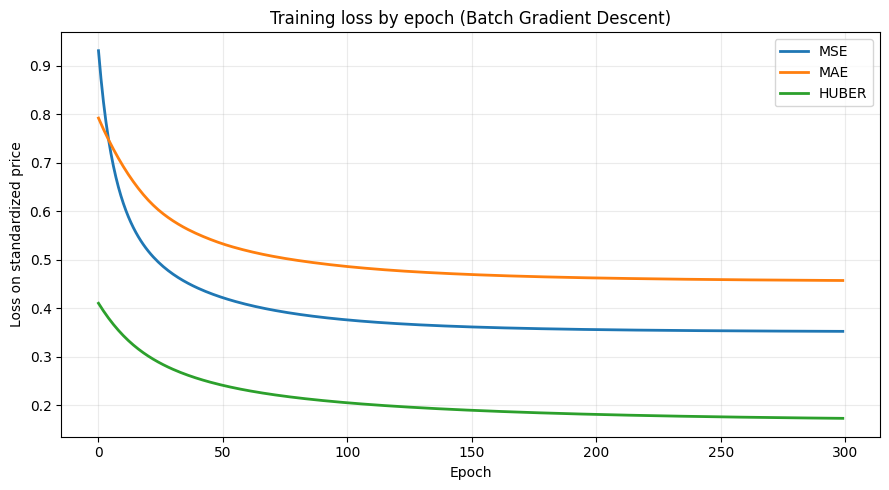

,Epoch 1,Final
Loss,,
MSE,0.9311,0.3522
MAE,0.7922,0.4571
HUBER,0.4102,0.1728


In [6]:
EPOCHS = 300
LEARNING_RATE = 0.03
METHOD = "batch"  # Change to "sgd" and lower LEARNING_RATE (for example, 0.0005) to compare SGD.

models = {
    loss_name: train_linear_regression(
        X_train,
        y_train,
        loss=loss_name,
        method=METHOD,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        seed=RANDOM_SEED,
    )
    for loss_name in ("mse", "mae", "huber")
}

plt.figure(figsize=(9, 5))
for loss_name, model in models.items():
    plt.plot(model["history"], label=loss_name.upper(), linewidth=2)
plt.title(f"Training loss by epoch ({METHOD.title()} Gradient Descent)")
plt.xlabel("Epoch")
plt.ylabel("Loss on standardized price")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame([
    {"Loss": name.upper(), "Epoch 1": model["history"][0], "Final": model["history"][-1]}
    for name, model in models.items()
]).set_index("Loss").round(4)

## 6. Evaluate held-out homes

The selected model predicts standardized prices first; we convert them back to AUD before calculating mean absolute error (MAE) and root mean squared error (RMSE). Lower values mean smaller average prediction errors on this test split. Linear regression is a simple baseline and can miss nonlinear relationships or interactions between features.

In [7]:
selected_model = models["mse"]  # Try "mae" or "huber" to inspect a different objective.
test_predictions = predict_scaled(selected_model, X_test) * y_scale + y_mean

mae_aud = np.mean(np.abs(test_predictions - price_test))
rmse_aud = np.sqrt(np.mean((test_predictions - price_test) ** 2))
mean_baseline_mae = np.mean(np.abs(price_test.mean() - price_test))

metrics = pd.DataFrame(
    {"Metric": ["MAE", "RMSE", "Mean-price baseline MAE"],
     "AUD": [mae_aud, rmse_aud, mean_baseline_mae]}
).set_index("Metric")
metrics.round(0)

,AUD
Metric,
MAE,239246.0
RMSE,310435.0
Mean-price baseline MAE,420509.0


In [8]:
results = test_rows[["Rooms", "Type", "Distance", "Bathroom", "Car", "Region", "Price"]].copy()
results["Predicted price"] = test_predictions
results["Absolute error"] = np.abs(results["Price"] - results["Predicted price"])
results[["Price", "Predicted price", "Absolute error"]] = results[["Price", "Predicted price", "Absolute error"]].round(0)
display(results.head(10))

,Rooms,Type,Distance,Bathroom,Car,Region,Price,Predicted price,Absolute error
0,2.0,h,8.4,1.0,1.0,Western Metropolitan,820000.0,765151.0,54849.0
1,4.0,h,3.5,3.0,2.0,Southern Metropolitan,2372500.0,2094939.0,277561.0
2,3.0,h,41.0,2.0,2.0,Eastern Victoria,565500.0,199289.0,366211.0
3,2.0,h,7.0,2.0,2.0,Western Metropolitan,630000.0,975842.0,345842.0
4,4.0,h,9.2,2.0,2.0,Western Metropolitan,1060000.0,1225942.0,165942.0
5,3.0,h,6.9,2.0,1.0,Western Metropolitan,1250000.0,1117749.0,132251.0
6,3.0,t,5.6,1.0,2.0,Southern Metropolitan,690000.0,1297922.0,607922.0
7,2.0,u,9.9,1.0,1.0,Northern Metropolitan,497000.0,263788.0,233212.0
8,2.0,u,11.8,2.0,2.0,Eastern Metropolitan,725000.0,592202.0,132798.0
9,2.0,h,8.4,1.0,2.0,Northern Metropolitan,960000.0,844612.0,115388.0


## 7. What to take away

1. Linear regression combines each home feature with a learned weight and adds a bias to produce a price estimate.
2. A loss function turns prediction errors into a score. Its gradient indicates how changing the predictions changes that score.
3. Gradient descent applies those gradients to improve the weights and bias. Feature and target scaling make the updates easier to tune.
4. MSE emphasizes large errors, MAE reduces their influence, and Huber transitions between the two behaviors.
5. A falling training curve only shows improvement on training data. Use held-out metrics to estimate how the model performs on homes it did not train on.

This notebook is an educational implementation. The dataset split and test metrics make evaluation visible, but the result is not a formal property valuation.